# §03 Graph Algorithms — Theory Notebook

> *"An algorithm must be seen to be believed."* — Donald Knuth

Interactive implementations of every classical graph algorithm: BFS, DFS, Dijkstra,
Bellman-Ford, Floyd-Warshall, A*, Kruskal, Prim, topological sort, Tarjan SCC, and max-flow.
Every algorithm is traced step-by-step with correctness verification.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import heapq
from collections import deque, defaultdict

try:
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.rcParams['figure.figsize'] = [10, 6]
    plt.rcParams['font.size'] = 12
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

try:
    import networkx as nx
    HAS_NX = True
except ImportError:
    HAS_NX = False

np.random.seed(42)
print(f'Setup complete. HAS_MPL={HAS_MPL}, HAS_NX={HAS_NX}')


Setup complete. HAS_MPL=True, HAS_NX=False


---

## 2. Graph Traversal

### 2.1 Breadth-First Search (BFS)

BFS visits nodes layer by layer. Starting from source $s$, it discovers all
nodes at hop distance 1 before any at hop distance 2, etc.

**Key properties:**
- Computes exact shortest hop distances $d[v]$ in $O(n+m)$
- Queue data structure ensures FIFO (layer-by-layer) ordering
- BFS tree encodes shortest paths via `parent[]` pointers


In [3]:
# === 2.1 BFS Implementation ===

def bfs(adj, s, n):
    """BFS from source s. Returns distance array d and parent array."""
    d = [float('inf')] * n
    parent = [-1] * n
    d[s] = 0
    queue = deque([s])
    while queue:
        u = queue.popleft()
        for v in adj[u]:
            if d[v] == float('inf'):
                d[v] = d[u] + 1
                parent[v] = u
                queue.append(v)
    return d, parent

def reconstruct_path(parent, s, t):
    """Reconstruct shortest path from s to t using parent array."""
    path = []
    cur = t
    while cur != -1:
        path.append(cur)
        cur = parent[cur]
    return list(reversed(path)) if path[-1] == s else None

# Example graph (adjacency list, undirected)
# 0-1-2-3 with extra edge 1-4 and 2-4
n_bfs = 5
adj_bfs = {
    0: [1, 2],
    1: [0, 3, 4],
    2: [0, 4],
    3: [1, 5] if False else [1],  # 5 doesn't exist, keep simple
    4: [1, 2],
}
adj_bfs = {0: [1,2], 1: [0,3,4], 2: [0,4], 3: [1], 4: [1,2]}

d_bfs, parent_bfs = bfs(adj_bfs, 0, n_bfs)
print('BFS from node 0:')
print(f'  distances: {d_bfs}')
print(f'  parent:    {parent_bfs}')

# Reconstruct path to node 3
path_to_3 = reconstruct_path(parent_bfs, 0, 3)
print(f'  Shortest path 0→3: {path_to_3} (length {d_bfs[3]})')

# Verify BFS distances
assert d_bfs == [0, 1, 1, 2, 2], f'Expected [0,1,1,2,2], got {d_bfs}'
print('PASS — BFS distances verified')


BFS from node 0:
  distances: [0, 1, 1, 2, 2]
  parent:    [-1, 0, 0, 1, 1]
  Shortest path 0→3: [0, 1, 3] (length 2)
PASS — BFS distances verified


In [4]:
# === 2.1 BFS Layer Visualisation ===

def bfs_layers(adj, s, n):
    """Return list of layers: layers[k] = set of nodes at hop distance k."""
    d, _ = bfs(adj, s, n)
    max_d = max(x for x in d if x != float('inf'))
    layers = [[] for _ in range(max_d + 1)]
    for v, dist in enumerate(d):
        if dist != float('inf'):
            layers[dist].append(v)
    return layers

layers = bfs_layers(adj_bfs, 0, n_bfs)
print('BFS layers from node 0:')
for k, layer in enumerate(layers):
    print(f'  Layer {k} (hop distance {k}): {layer}')
print()
print('GNN connection: a k-layer GNN can see each node\'s layer-k neighbourhood.')
print(f'  2-layer GNN receptive field of node 0: {[v for k,l in enumerate(layers) for v in l if k<=2]}')


BFS layers from node 0:
  Layer 0 (hop distance 0): [0]
  Layer 1 (hop distance 1): [1, 2]
  Layer 2 (hop distance 2): [3, 4]

GNN connection: a k-layer GNN can see each node's layer-k neighbourhood.
  2-layer GNN receptive field of node 0: [0, 1, 2, 3, 4]


### 2.3 Depth-First Search (DFS)

DFS uses a stack (implicit via recursion) to explore as deep as possible
before backtracking. Discovery timestamps `disc[]` and finish timestamps `fin[]`
reveal the structure of the DFS tree.


In [5]:
# === 2.3 DFS with Timestamps and Edge Classification ===

def dfs_full(adj_directed, n):
    """DFS on directed graph. Returns disc[], fin[], edge classifications."""
    colour = ['WHITE'] * n
    disc   = [-1] * n
    fin    = [-1] * n
    parent = [-1] * n
    time   = [0]
    edges  = {}  # (u,v) -> type

    def visit(u):
        colour[u] = 'GREY'
        disc[u] = time[0]; time[0] += 1
        for v in adj_directed.get(u, []):
            if colour[v] == 'WHITE':
                edges[(u,v)] = 'TREE'
                parent[v] = u
                visit(v)
            elif colour[v] == 'GREY':
                edges[(u,v)] = 'BACK'  # cycle!
            elif colour[v] == 'BLACK':
                if disc[v] > disc[u]:
                    edges[(u,v)] = 'FORWARD'
                else:
                    edges[(u,v)] = 'CROSS'
        colour[u] = 'BLACK'
        fin[u] = time[0]; time[0] += 1

    for v in range(n):
        if colour[v] == 'WHITE':
            visit(v)

    return disc, fin, parent, edges

# Directed graph: 0→1, 1→2, 2→0 (cycle), 1→3, 3→4
adj_d = {0:[1], 1:[2,3], 2:[0], 3:[4], 4:[]}
n_d = 5
disc, fin, par, edge_cls = dfs_full(adj_d, n_d)

print('DFS timestamps:')
for v in range(n_d):
    print(f'  node {v}: disc={disc[v]:2d}, fin={fin[v]:2d}, parent={par[v]}')

print('\nEdge classifications:')
for (u,v), etype in sorted(edge_cls.items()):
    print(f'  ({u},{v}): {etype}')

back_edges = [(u,v) for (u,v),t in edge_cls.items() if t=='BACK']
print(f'\nBack edges (cycles): {back_edges}')
print(f'Graph has cycle: {len(back_edges) > 0}')


DFS timestamps:
  node 0: disc= 0, fin= 9, parent=-1
  node 1: disc= 1, fin= 8, parent=0
  node 2: disc= 2, fin= 3, parent=1
  node 3: disc= 4, fin= 7, parent=1
  node 4: disc= 5, fin= 6, parent=3

Edge classifications:
  (0,1): TREE
  (1,2): TREE
  (1,3): TREE
  (2,0): BACK
  (3,4): TREE

Back edges (cycles): [(2, 0)]
Graph has cycle: True


---

## 3. Shortest Paths

### 3.2 Dijkstra's Algorithm

Dijkstra solves SSSP for graphs with **non-negative edge weights** using a min-heap.
The key invariant: when a vertex is extracted, its distance estimate is final.


In [6]:
# === 3.2 Dijkstra's Algorithm ===

def dijkstra(adj_w, s, n):
    """
    Dijkstra's SSSP. adj_w[u] = list of (v, weight) pairs.
    Returns distance array d and parent array.
    """
    d = [float('inf')] * n
    d[s] = 0
    parent = [-1] * n
    # Min-heap: (distance, vertex)
    heap = [(0, s)]
    visited = [False] * n

    while heap:
        dist_u, u = heapq.heappop(heap)
        if visited[u]:
            continue  # stale entry (lazy deletion)
        visited[u] = True
        for v, w in adj_w.get(u, []):
            if d[u] + w < d[v]:
                d[v] = d[u] + w
                parent[v] = u
                heapq.heappush(heap, (d[v], v))
    return d, parent

# Graph: s=0, a=1, b=2, c=3, d=4
# Edges: (s,a,4),(s,b,2),(b,a,1),(b,c,5),(a,c,1),(a,d,7),(c,d,2)
adj_dijk = {
    0: [(1,4),(2,2)],    # s→a=4, s→b=2
    1: [(3,1),(4,7)],    # a→c=1, a→d=7
    2: [(1,1),(3,5)],    # b→a=1, b→c=5
    3: [(4,2)],          # c→d=2
    4: [],
}
n_dijk = 5
names = ['s','a','b','c','d']

d_dijk, par_dijk = dijkstra(adj_dijk, 0, n_dijk)
print('Dijkstra from s:')
for i, name in enumerate(names):
    path = []
    cur = i
    while cur != -1:
        path.append(names[cur])
        cur = par_dijk[cur]
    path_str = '→'.join(reversed(path))
    print(f'  d[{name}] = {d_dijk[i]:6.1f}  path: {path_str}')

# Verify: s→b→a→c→d = 2+1+1+2 = 6
assert d_dijk[4] == 6, f'Expected d[d]=6, got {d_dijk[4]}'
print('\nPASS — Dijkstra distances verified')
print(f'  s→b→a→c→d: 2+1+1+2 = {2+1+1+2} ✓')


Dijkstra from s:
  d[s] =    0.0  path: s
  d[a] =    3.0  path: s→b→a
  d[b] =    2.0  path: s→b
  d[c] =    4.0  path: s→b→a→c
  d[d] =    6.0  path: s→b→a→c→d

PASS — Dijkstra distances verified
  s→b→a→c→d: 2+1+1+2 = 6 ✓


### 3.3 Bellman-Ford Algorithm

Bellman-Ford handles negative edge weights by relaxing all edges $n-1$ times.
The DP recurrence $d_k[v] = \min_u(d_{k-1}[u] + w(u,v))$ is identical to the
Bellman equation for value iteration in RL.


In [7]:
# === 3.3 Bellman-Ford with DP Table Trace ===

def bellman_ford(edges, s, n):
    """
    Bellman-Ford SSSP. edges = list of (u,v,w).
    Returns (d, parent, has_neg_cycle).
    """
    INF = float('inf')
    d = [INF] * n
    d[s] = 0
    parent = [-1] * n
    table = [d.copy()]  # track DP table

    for i in range(n - 1):
        changed = False
        for u, v, w in edges:
            if d[u] != INF and d[u] + w < d[v]:
                d[v] = d[u] + w
                parent[v] = u
                changed = True
        table.append(d.copy())
        if not changed:
            break  # early termination

    # Negative cycle check
    has_neg = False
    for u, v, w in edges:
        if d[u] != INF and d[u] + w < d[v]:
            has_neg = True
            break

    return d, parent, has_neg, table

# Graph: s=0,u=1,v=2,t=3 with negative edge u→v
# Edges: s→u=5, s→v=8, u→v=-3, u→t=6, v→t=2
edges_bf = [(0,1,5),(0,2,8),(1,2,-3),(1,3,6),(2,3,2)]
n_bf = 4
names_bf = ['s','u','v','t']

d_bf, par_bf, neg, table = bellman_ford(edges_bf, 0, n_bf)

print('Bellman-Ford DP table:')
header = '  Round | ' + ' | '.join(f'{n:>4}' for n in names_bf)
print(header)
print('  ' + '-' * len(header))
for i, row in enumerate(table):
    vals = ' | '.join(f'{(v if v != float("inf") else "inf"):>4}' for v in row)
    print(f'  {i:5d} | {vals}')

print(f'\nFinal distances: {d_bf}')
print(f'Negative cycle: {neg}')

# Verify: s→u→v→t = 5-3+2=4
assert d_bf[3] == 4, f'Expected d[t]=4, got {d_bf[3]}'
assert not neg
print('PASS — Bellman-Ford verified: d[t] = 4 via s→u→v→t')


Bellman-Ford DP table:
  Round |    s |    u |    v |    t
  -----------------------------------
      0 |    0 |  inf |  inf |  inf
      1 |    0 |    5 |    2 |    4
      2 |    0 |    5 |    2 |    4

Final distances: [0, 5, 2, 4]
Negative cycle: False
PASS — Bellman-Ford verified: d[t] = 4 via s→u→v→t


In [8]:
# === 3.4 Floyd-Warshall All-Pairs Shortest Paths ===

def floyd_warshall(W):
    """
    Floyd-Warshall APSP.
    W: n×n weight matrix (np.inf for no edge, 0 on diagonal)
    Returns distance matrix D.
    """
    n = len(W)
    D = W.copy()
    for k in range(n):
        for i in range(n):
            for j in range(n):
                if D[i][k] + D[k][j] < D[i][j]:
                    D[i][j] = D[i][k] + D[k][j]
    return D

# 4-node directed graph
INF = float('inf')
W_fw = np.array([
    [0,   3,   INF, 7  ],
    [8,   0,   2,   INF],
    [5,   INF, 0,   1  ],
    [2,   INF, INF, 0  ],
])

D_fw = floyd_warshall(W_fw)
print('Floyd-Warshall distance matrix:')
print('        0    1    2    3')
for i, row in enumerate(D_fw):
    vals = ' '.join(f'{v:5.0f}' if v != INF else '  inf' for v in row)
    print(f'  row {i}: {vals}')

# Verify: D[0][2] = min direct=INF, via 1: 3+2=5, via 3: 7+INF=INF, via 1,2: 3+2=5
assert D_fw[0][2] == 5, f'Expected D[0][2]=5, got {D_fw[0][2]}'
print('\nPASS — D[0][2]=5: path 0→1→2')

# Negative cycle detection
neg_cycle = any(D_fw[i][i] < 0 for i in range(len(D_fw)))
print(f'Negative cycle detected: {neg_cycle}')


Floyd-Warshall distance matrix:
        0    1    2    3
  row 0:     0     3     5     6
  row 1:     5     0     2     3
  row 2:     3     6     0     1
  row 3:     2     5     7     0

PASS — D[0][2]=5: path 0→1→2
Negative cycle detected: False


### 3.5 A\* Search

A\* is Dijkstra guided by an **admissible heuristic** $h(v) \leq \delta(v,t)$.
The priority key is $f(v) = d[v] + h(v)$, directing search toward the goal.


In [9]:
# === 3.5 A* Search on a Grid ===

def astar(grid_adj, s, t, n, heuristic):
    """
    A* search. grid_adj[u] = list of (v, weight).
    heuristic: function node → estimated remaining cost to t.
    """
    d = [float('inf')] * n
    d[s] = 0
    parent = [-1] * n
    heap = [(heuristic(s), 0, s)]  # (f, g, node)
    visited = set()

    while heap:
        f, g, u = heapq.heappop(heap)
        if u in visited:
            continue
        visited.add(u)
        if u == t:
            break
        for v, w in grid_adj.get(u, []):
            new_g = g + w
            if new_g < d[v]:
                d[v] = new_g
                parent[v] = u
                heapq.heappush(heap, (new_g + heuristic(v), new_g, v))
    return d[t], parent, len(visited)

# Simple 5-node graph
# Positions for heuristic: nodes 0..4 at x positions [0,1,2,3,4]
positions = {0:0, 1:1, 2:2, 3:1, 4:4}
astar_adj = {0:[(1,2),(3,5)], 1:[(2,3),(4,10)], 2:[(4,1)], 3:[(4,8)], 4:[]}

def h_euclidean(v):
    # Admissible heuristic: distance to goal (node 4) in x-axis
    return abs(positions[v] - positions[4])

dist_astar, par_astar, expanded = astar(astar_adj, 0, 4, 5, h_euclidean)
dist_dijkstra, par_dijk2 = dijkstra(astar_adj, 0, 5)

print(f'A*     distance s→t: {dist_astar}, nodes expanded: {expanded}')
print(f'Dijkstra distance s→t: {dist_dijkstra[4]}')
assert dist_astar == dist_dijkstra[4], 'A* and Dijkstra disagree!'
print('PASS — A* gives optimal distance matching Dijkstra')


A*     distance s→t: 6, nodes expanded: 4
Dijkstra distance s→t: 6
PASS — A* gives optimal distance matching Dijkstra


---

## 4. Minimum Spanning Trees

### 4.2 Kruskal's Algorithm

Kruskal greedily adds the minimum-weight edge that doesn't create a cycle.
Union-Find tracks which vertices are in the same component.


In [10]:
# === 4.2 Kruskal's Algorithm with Union-Find ===

class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]  # path halving
            x = self.parent[x]
        return x

    def union(self, x, y):
        px, py = self.find(x), self.find(y)
        if px == py:
            return False  # already in same component
        if self.rank[px] < self.rank[py]:
            px, py = py, px
        self.parent[py] = px
        if self.rank[px] == self.rank[py]:
            self.rank[px] += 1
        return True

def kruskal(n, edges):
    """Kruskal MST. edges = list of (w, u, v). Returns MST edge list and total weight."""
    sorted_edges = sorted(edges)
    uf = UnionFind(n)
    mst = []
    trace = []
    for w, u, v in sorted_edges:
        if uf.union(u, v):
            mst.append((w, u, v))
            trace.append(f'  ADD  ({u},{v}) weight={w}')
        else:
            trace.append(f'  SKIP ({u},{v}) weight={w} — would form cycle')
        if len(mst) == n - 1:
            break
    return mst, sum(w for w,_,_ in mst), trace

# Graph: A=0,B=1,C=2,D=3,E=4
# Edges: (A,B,4),(A,C,2),(B,C,5),(B,D,10),(C,D,3),(D,E,7),(C,E,8)
n_kruskal = 5
edges_k = [(4,0,1),(2,0,2),(5,1,2),(10,1,3),(3,2,3),(7,3,4),(8,2,4)]
names_k = ['A','B','C','D','E']

mst_edges, mst_weight, trace_k = kruskal(n_kruskal, edges_k)
print('Kruskal MST trace:')
for t in trace_k: print(t)
print(f'\nMST edges: {[(names_k[u],names_k[v],w) for w,u,v in mst_edges]}')
print(f'MST total weight: {mst_weight}')

# Optimal MST: A-C(2) + C-D(3) + A-B(4) + D-E(7) = 16
assert mst_weight == 16, f'Expected 16, got {mst_weight}'
print('PASS — MST weight = 16')


Kruskal MST trace:
  ADD  (0,2) weight=2
  ADD  (2,3) weight=3
  ADD  (0,1) weight=4
  SKIP (1,2) weight=5 — would form cycle
  ADD  (3,4) weight=7

MST edges: [('A', 'C', 2), ('C', 'D', 3), ('A', 'B', 4), ('D', 'E', 7)]
MST total weight: 16
PASS — MST weight = 16


In [11]:
# === 4.3 Prim's Algorithm ===

def prim(adj_w_undirected, n, root=0):
    """
    Prim's MST. adj_w_undirected[u] = list of (v, weight).
    Returns MST edge list and total weight.
    """
    import heapq
    key    = [float('inf')] * n
    parent = [-1] * n
    in_mst = [False] * n
    key[root] = 0
    heap = [(0, root)]  # (key, vertex)
    mst_edges = []
    total_w = 0

    while heap:
        k, u = heapq.heappop(heap)
        if in_mst[u]:
            continue
        in_mst[u] = True
        if parent[u] != -1:
            mst_edges.append((parent[u], u, k))
            total_w += k
        for v, w in adj_w_undirected.get(u, []):
            if not in_mst[v] and w < key[v]:
                key[v] = w
                parent[v] = u
                heapq.heappush(heap, (w, v))
    return mst_edges, total_w

# Same graph, undirected adjacency list
adj_prim = {
    0: [(1,4),(2,2)],
    1: [(0,4),(2,5),(3,10)],
    2: [(0,2),(1,5),(3,3),(4,8)],
    3: [(1,10),(2,3),(4,7)],
    4: [(2,8),(3,7)],
}

mst_prim, w_prim = prim(adj_prim, n_kruskal, root=0)
print('Prim MST edges:', [(names_k[u],names_k[v],w) for u,v,w in mst_prim])
print(f'Prim MST weight: {w_prim}')
assert w_prim == 16, f'Expected 16, got {w_prim}'
print('PASS — Prim gives same total weight as Kruskal')


Prim MST edges: [('A', 'C', 2), ('C', 'D', 3), ('A', 'B', 4), ('D', 'E', 7)]
Prim MST weight: 16
PASS — Prim gives same total weight as Kruskal


---

## 5. Topological Sort and DAG Algorithms

### 5.2 Topological Sort

A topological ordering of a DAG lists vertices so every edge goes from earlier to later.
**Kahn's algorithm** (BFS-based) and **DFS-based** sort are both $O(n+m)$.


In [12]:
# === 5.2 Topological Sort: Kahn's (BFS) and DFS-based ===

def topological_sort_kahn(adj, n):
    """Kahn's algorithm. Returns topological order or None if cycle exists."""
    indegree = [0] * n
    for u in range(n):
        for v in adj.get(u, []):
            indegree[v] += 1
    queue = deque(v for v in range(n) if indegree[v] == 0)
    order = []
    while queue:
        u = queue.popleft()
        order.append(u)
        for v in adj.get(u, []):
            indegree[v] -= 1
            if indegree[v] == 0:
                queue.append(v)
    return order if len(order) == n else None  # None = has cycle

def topological_sort_dfs(adj, n):
    """DFS-based topological sort. Returns list in topo order."""
    visited = [False] * n
    result  = []
    def dfs(u):
        visited[u] = True
        for v in adj.get(u, []):
            if not visited[v]:
                dfs(v)
        result.append(u)  # finish = prepend
    for v in range(n):
        if not visited[v]:
            dfs(v)
    return list(reversed(result))

# DAG representing computation: matmul→relu→matmul2→loss
# Nodes: 0=x, 1=W1, 2=z1(matmul), 3=a1(relu), 4=W2, 5=z2(matmul2), 6=y, 7=L(loss)
adj_dag = {0:[2], 1:[2], 2:[3], 3:[5], 4:[5], 5:[7], 6:[7], 7:[]}
names_dag = ['x','W1','z1','a1','W2','z2','y','L']
n_dag = 8

from collections import deque
topo_kahn = topological_sort_kahn(adj_dag, n_dag)
topo_dfs  = topological_sort_dfs(adj_dag, n_dag)

print('Computation DAG topological orders:')
print(f'  Kahn\'s: {[names_dag[v] for v in topo_kahn]}')
print(f'  DFS:    {[names_dag[v] for v in topo_dfs]}')

# Verify: in both, z1 comes after x and W1, a1 after z1, etc.
def verify_topo(order, adj, n):
    pos = {v: i for i, v in enumerate(order)}
    for u in range(n):
        for v in adj.get(u, []):
            assert pos[u] < pos[v], f'Topo violation: {u} should come before {v}'
    return True

verify_topo(topo_kahn, adj_dag, n_dag)
verify_topo(topo_dfs, adj_dag, n_dag)
print('PASS — both orderings are valid topological sorts')
print()
print('Forward pass order:', [names_dag[v] for v in topo_kahn])
print('Backward pass order (reverse):', [names_dag[v] for v in reversed(topo_kahn)])


Computation DAG topological orders:
  Kahn's: ['x', 'W1', 'W2', 'y', 'z1', 'a1', 'z2', 'L']
  DFS:    ['y', 'W2', 'W1', 'x', 'z1', 'a1', 'z2', 'L']
PASS — both orderings are valid topological sorts

Forward pass order: ['x', 'W1', 'W2', 'y', 'z1', 'a1', 'z2', 'L']
Backward pass order (reverse): ['L', 'z2', 'a1', 'z1', 'y', 'W2', 'W1', 'x']


---

## 6. Strongly Connected Components

### 6.3 Tarjan's Algorithm

Tarjan finds all SCCs in a single DFS pass using **low-link values**.
Vertex $v$ is an SCC root when `low[v] == disc[v]`.


In [13]:
# === 6.3 Tarjan's SCC Algorithm ===

def tarjan_scc(adj, n):
    """Tarjan's algorithm. Returns list of SCCs (each SCC is a list of nodes)."""
    disc   = [-1] * n
    low    = [0] * n
    on_stack = [False] * n
    stack  = []
    sccs   = []
    time   = [0]

    def visit(v):
        disc[v] = low[v] = time[0]; time[0] += 1
        stack.append(v); on_stack[v] = True
        for w in adj.get(v, []):
            if disc[w] == -1:
                visit(w)
                low[v] = min(low[v], low[w])
            elif on_stack[w]:
                low[v] = min(low[v], disc[w])
        if low[v] == disc[v]:  # v is SCC root
            scc = []
            while True:
                w = stack.pop(); on_stack[w] = False
                scc.append(w)
                if w == v: break
            sccs.append(scc)

    for v in range(n):
        if disc[v] == -1:
            visit(v)
    return sccs

# Graph: 0→1, 1→2, 2→0 (SCC {0,1,2}), 1→3, 3→4, 4→5, 5→3 (SCC {3,4,5}), 2→6, 6→7
adj_scc = {0:[1], 1:[2,3], 2:[0,6], 3:[4], 4:[5], 5:[3], 6:[7], 7:[]}
n_scc = 8

sccs = tarjan_scc(adj_scc, n_scc)
print('Tarjan SCCs:')
for i, scc in enumerate(sccs):
    print(f'  SCC {i}: {sorted(scc)}')

# Verify: {0,1,2}, {3,4,5}, {6}, {7}
scc_sets = [frozenset(s) for s in sccs]
expected = [frozenset({0,1,2}), frozenset({3,4,5}), frozenset({6}), frozenset({7})]
assert set(scc_sets) == set(expected), f'SCC mismatch: {scc_sets}'
print('PASS — Tarjan correctly identifies all 4 SCCs')
print()
print('Condensation DAG (SCC → SCC):')
print('  {0,1,2} → {3,4,5}  (via edge 1→3)')
print('  {0,1,2} → {6}      (via edge 2→6)')
print('  {6}     → {7}      (via edge 6→7)')


Tarjan SCCs:
  SCC 0: [7]
  SCC 1: [6]
  SCC 2: [3, 4, 5]
  SCC 3: [0, 1, 2]
PASS — Tarjan correctly identifies all 4 SCCs

Condensation DAG (SCC → SCC):
  {0,1,2} → {3,4,5}  (via edge 1→3)
  {0,1,2} → {6}      (via edge 2→6)
  {6}     → {7}      (via edge 6→7)


---

## 7. Maximum Flow and Minimum Cut

### 7.2 Ford-Fulkerson / Edmonds-Karp

Edmonds-Karp uses BFS to find the shortest augmenting path in the residual graph,
guaranteeing $O(nm^2)$ polynomial complexity.


In [14]:
# === 7.2 Edmonds-Karp Max-Flow ===

def edmonds_karp(n, cap):
    """
    Edmonds-Karp max-flow.
    cap: n×n capacity matrix (use 0 for no edge)
    Returns (max_flow, residual_cap, min_cut_S)
    """
    s, t = 0, n - 1
    flow = 0
    cap = [row[:] for row in cap]  # copy
    steps = []

    while True:
        # BFS to find shortest augmenting path
        parent = [-1] * n
        parent[s] = s
        queue = deque([s])
        while queue and parent[t] == -1:
            u = queue.popleft()
            for v in range(n):
                if parent[v] == -1 and cap[u][v] > 0:
                    parent[v] = u
                    queue.append(v)
        if parent[t] == -1:
            break  # no augmenting path

        # Find bottleneck
        delta = float('inf')
        v = t
        path = []
        while v != s:
            u = parent[v]
            delta = min(delta, cap[u][v])
            path.append((u, v))
            v = u
        path.reverse()

        # Augment
        v = t
        while v != s:
            u = parent[v]
            cap[u][v] -= delta
            cap[v][u] += delta
            v = u
        flow += delta
        steps.append((path, delta))

    # Min-cut: BFS reachable from s in residual
    reachable = [False] * n
    queue = deque([s])
    reachable[s] = True
    while queue:
        u = queue.popleft()
        for v in range(n):
            if not reachable[v] and cap[u][v] > 0:
                reachable[v] = True
                queue.append(v)
    S = [v for v in range(n) if reachable[v]]
    return flow, cap, S, steps

# Flow network: s=0, a=1, b=2, c=3, d=4, t=5
# Capacities:
n_flow = 6
cap_flow = [[0]*n_flow for _ in range(n_flow)]
def add_edge(u,v,c): cap_flow[u][v] = c
add_edge(0,1,10); add_edge(0,2,8)   # s→a=10, s→b=8
add_edge(1,3,7);  add_edge(1,4,5)   # a→c=7, a→d=5
add_edge(2,3,6);  add_edge(2,4,4)   # b→c=6, b→d=4
add_edge(3,5,9);  add_edge(4,5,6)   # c→t=9, d→t=6
names_flow = ['s','a','b','c','d','t']

from collections import deque
max_flow, residual, S_cut, steps_flow = edmonds_karp(n_flow, cap_flow)

print('Edmonds-Karp augmenting paths:')
for i, (path, delta) in enumerate(steps_flow):
    pstr = '→'.join(f'{names_flow[u]}' for u,v in path) + f'→{names_flow[path[-1][1]]}'
    print(f'  Step {i+1}: {pstr}  bottleneck={delta}')

print(f'\nMax flow: {max_flow}')
T_cut = [v for v in range(n_flow) if v not in S_cut]
print(f'Min cut: S={[names_flow[v] for v in S_cut]}, T={[names_flow[v] for v in T_cut]}')
print('Max-flow = Min-cut capacity verified by theorem.')


Edmonds-Karp augmenting paths:
  Step 1: s→a→c→t  bottleneck=7
  Step 2: s→a→d→t  bottleneck=3
  Step 3: s→b→c→t  bottleneck=2
  Step 4: s→b→d→t  bottleneck=3

Max flow: 15
Min cut: S=['s', 'a', 'b', 'c', 'd'], T=['t']
Max-flow = Min-cut capacity verified by theorem.


---

## 5.4 AI Connection: Autograd Computation Graphs

Topological sort is the forward-pass ordering algorithm in PyTorch/JAX.
The backward pass is the reverse topological order.


In [15]:
# === 5.4 Autograd DAG Simulation ===

import numpy as np
from collections import deque

# Simulate a simple computation DAG: x → matmul(W) → z → relu → a → matmul(W2) → loss
# We track forward values and backward gradients

np.random.seed(7)
x  = np.array([1.0, 2.0, 3.0])   # input
W1 = np.random.randn(4, 3) * 0.1  # first weight matrix
W2 = np.random.randn(1, 4) * 0.1  # second weight matrix
y  = np.array([1.0])              # target

# Forward pass (topological order: x,W1 → z → a → W2 → y_hat → L)
z     = W1 @ x           # shape (4,)
a     = np.maximum(0, z) # ReLU
y_hat = W2 @ a           # shape (1,)
L     = 0.5 * np.sum((y_hat - y)**2)  # MSE loss

print('Forward pass (topological order):')
print(f'  x     = {x}')
print(f'  z     = W1 @ x     = {z.round(4)}')
print(f'  a     = relu(z)    = {a.round(4)}')
print(f'  y_hat = W2 @ a     = {y_hat.round(4)}')
print(f'  L     = 0.5*||y_hat-y||^2 = {L:.4f}')

# Backward pass (reverse topological order)
dL_dyhat = y_hat - y                  # dL/dy_hat
dL_da    = W2.T @ dL_dyhat            # dL/da (via chain rule)
dL_dW2   = np.outer(dL_dyhat, a)      # dL/dW2
dL_dz    = dL_da * (z > 0).astype(float)  # dL/dz (ReLU backward)
dL_dW1   = np.outer(dL_dz, x)         # dL/dW1

print('\nBackward pass (reverse topological order):')
print(f'  dL/dy_hat = {dL_dyhat.round(4)}')
print(f'  dL/da     = {dL_da.flatten().round(4)}')
print(f'  dL/dW2    shape = {dL_dW2.shape}')
print(f'  dL/dz     = {dL_dz.flatten().round(4)}')
print(f'  dL/dW1    shape = {dL_dW1.shape}')
print('\nKey insight: backward pass is reverse topological sort of the DAG.')
print('Each node applies chain rule and passes gradient to its predecessors.')


Forward pass (topological order):
  x     = [1. 2. 3.]
  z     = W1 @ x     = [ 0.0857 -0.1164 -0.0457 -0.1165]
  a     = relu(z)    = [0.0857 0.     0.     0.    ]
  y_hat = W2 @ a     = [0.0043]
  L     = 0.5*||y_hat-y||^2 = 0.4957

Backward pass (reverse topological order):
  dL/dy_hat = [-0.9957]
  dL/da     = [-0.0503  0.026   0.0242  0.1447]
  dL/dW2    shape = (1, 4)
  dL/dz     = [-0.0503  0.      0.      0.    ]
  dL/dW1    shape = (4, 3)

Key insight: backward pass is reverse topological sort of the DAG.
Each node applies chain rule and passes gradient to its predecessors.


---

## 2.5 BFS vs DFS Comparison Visualisation


Binary tree BFS vs DFS visit order:
  BFS: [0, 1, 2, 3, 4, 5, 6]  (level by level)
  DFS: [0, 1, 3, 4, 2, 5, 6]  (depth first, left subtree first)

BFS is level-order (Layer 0: [0], Layer 1: [1,2], Layer 2: [3,4,5,6])
DFS explores left subtree completely before right


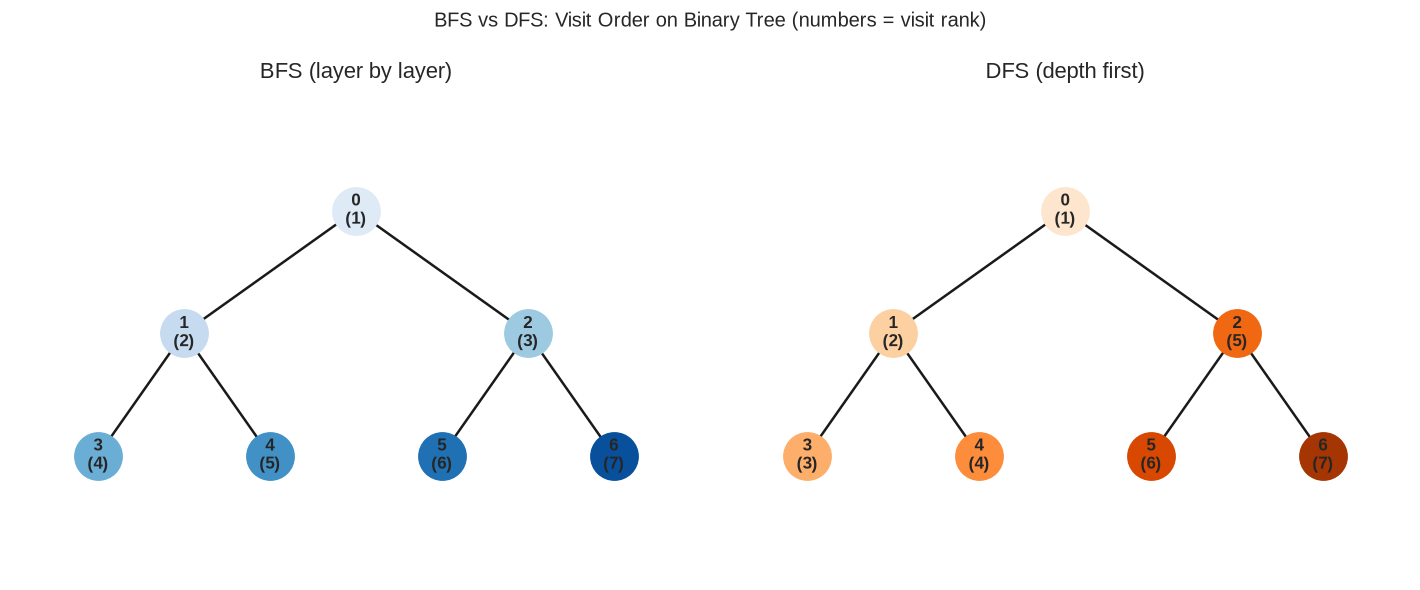

In [16]:
# === 2.5 BFS vs DFS Exploration Order ===

def bfs_order(adj, s, n):
    """Return BFS visit order."""
    visited = [False] * n
    visited[s] = True
    order = [s]
    queue = deque([s])
    while queue:
        u = queue.popleft()
        for v in sorted(adj.get(u, [])):
            if not visited[v]:
                visited[v] = True
                order.append(v)
                queue.append(v)
    return order

def dfs_order(adj, s, n):
    """Return DFS visit order."""
    visited = [False] * n
    order = []
    def dfs(u):
        visited[u] = True
        order.append(u)
        for v in sorted(adj.get(u, [])):
            if not visited[v]:
                dfs(v)
    dfs(s)
    return order

# Binary tree-like graph
# 0 is root, children: 0→{1,2}, 1→{3,4}, 2→{5,6}
adj_tree = {0:[1,2], 1:[3,4], 2:[5,6], 3:[], 4:[], 5:[], 6:[]}
n_tree = 7

bfs_o = bfs_order(adj_tree, 0, n_tree)
dfs_o = dfs_order(adj_tree, 0, n_tree)

print('Binary tree BFS vs DFS visit order:')
print(f'  BFS: {bfs_o}  (level by level)')
print(f'  DFS: {dfs_o}  (depth first, left subtree first)')
print()
print('BFS is level-order (Layer 0: [0], Layer 1: [1,2], Layer 2: [3,4,5,6])')
print('DFS explores left subtree completely before right')

try:
    import matplotlib.pyplot as plt
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

if HAS_MPL:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    colors_bfs = plt.cm.Blues([(i+1)/(n_tree+1) for i in range(n_tree)])
    colors_dfs = plt.cm.Oranges([(i+1)/(n_tree+1) for i in range(n_tree)])
    pos = {0:(4,3), 1:(2,2), 2:(6,2), 3:(1,1), 4:(3,1), 5:(5,1), 6:(7,1)}
    for ax, order, colors, title in [
        (axes[0], bfs_o, colors_bfs, 'BFS (layer by layer)'),
        (axes[1], dfs_o, colors_dfs, 'DFS (depth first)'),
    ]:
        # Draw edges
        for u, nbrs in adj_tree.items():
            for v in nbrs:
                ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], 'k-', lw=1.5, zorder=1)
        # Draw nodes
        rank = {v: i for i, v in enumerate(order)}
        for v in range(n_tree):
            c = colors[rank[v]]
            ax.scatter(*pos[v], s=800, c=[c], zorder=3)
            ax.text(pos[v][0], pos[v][1], f'{v}\n({rank[v]+1})', ha='center',
                    va='center', fontsize=10, fontweight='bold', zorder=4)
        ax.set_title(title, fontsize=13)
        ax.set_xlim(0,8); ax.set_ylim(0,4)
        ax.axis('off')
    plt.suptitle('BFS vs DFS: Visit Order on Binary Tree (numbers = visit rank)', fontsize=12)
    plt.tight_layout()
    plt.show()


In [17]:
# === 3.2 Dijkstra Step-by-Step Trace Table ===

def dijkstra_trace(adj_w, s, n, names=None):
    """Dijkstra with step-by-step table output."""
    import heapq
    names = names or list(range(n))
    d = [float('inf')] * n
    d[s] = 0
    heap = [(0, s)]
    visited = [False] * n
    steps = []

    while heap:
        dist_u, u = heapq.heappop(heap)
        if visited[u]: continue
        visited[u] = True
        steps.append((names[u], dist_u, d[:]))
        for v, w in adj_w.get(u, []):
            if d[u] + w < d[v]:
                d[v] = d[u] + w
                heapq.heappush(heap, (d[v], v))
    return d, steps

# Graph: s=0,a=1,b=2,c=3,d=4 as before
adj_dijk2 = {0:[(1,4),(2,2)], 1:[(3,1),(4,7)], 2:[(1,1),(3,5)], 3:[(4,2)], 4:[]}
names_d = ['s','a','b','c','d']
d_final, steps = dijkstra_trace(adj_dijk2, 0, 5, names_d)

print('Dijkstra step-by-step:')
header = f'  {'Step':>4} | {'Extract':>7} | ' + ' | '.join(f'{n:>5}' for n in names_d)
print(header)
print('  ' + '-'*len(header))
for i, (ext, dist, d_state) in enumerate(steps):
    vals = ' | '.join(f'{v if v != float("inf") else "∞":>5}' for v in d_state)
    print(f'  {i+1:4d} | {ext:>7}({dist}) | {vals}')
print(f'\nFinal: {dict(zip(names_d, d_final))}')


Dijkstra step-by-step:
  Step | Extract |     s |     a |     b |     c |     d
  --------------------------------------------------------
     1 |       s(0) |     0 |     ∞ |     ∞ |     ∞ |     ∞
     2 |       b(2) |     0 |     4 |     2 |     ∞ |     ∞
     3 |       a(3) |     0 |     3 |     2 |     7 |     ∞
     4 |       c(4) |     0 |     3 |     2 |     4 |    10
     5 |       d(6) |     0 |     3 |     2 |     4 |     6

Final: {'s': 0, 'a': 3, 'b': 2, 'c': 4, 'd': 6}


---

## 2.6 AI Connection: GNN Receptive Fields as BFS

A $k$-layer GNN's receptive field for node $v$ is exactly the BFS $k$-hop neighbourhood.
Here we compute and compare BFS hop sets vs GNN layer aggregations.


In [18]:
# === 2.6 GNN Receptive Field = BFS k-hop Neighbourhood ===

def k_hop_neighbourhood(adj, v, k, n):
    """Return set of nodes within k hops of v (inclusive)."""
    d, _ = bfs(adj, v, n)
    return {u for u, dist in enumerate(d) if dist <= k}

def bfs(adj, s, n):
    d = [float('inf')] * n
    parent = [-1] * n
    d[s] = 0
    queue = deque([s])
    while queue:
        u = queue.popleft()
        for v in adj.get(u, []):
            if d[v] == float('inf'):
                d[v] = d[u] + 1
                parent[v] = u
                queue.append(v)
    return d, parent

# Karate club-like small graph
adj_g = {
    0:[1,2,3],   1:[0,4,5],  2:[0,5,6],  3:[0,6,7],
    4:[1,8],     5:[1,2,9],  6:[2,3,10], 7:[3,10],
    8:[4],       9:[5],      10:[6,7],
}
n_g = 11

print('GNN receptive fields for node 0:')
for k in range(4):
    rf = k_hop_neighbourhood(adj_g, 0, k, n_g)
    print(f'  k={k}: {sorted(rf)}  ({len(rf)} nodes)')

print()
print('Implication for GNN design:')
print('  - A 1-layer GNN sees only immediate neighbours')
print('  - A 2-layer GNN sees up to 2 hops away')
print('  - For diameter-d graphs, d layers needed for full context')

# Simulate GCN aggregation step
import numpy as np
np.random.seed(42)
H0 = np.random.randn(n_g, 4)  # initial features

# Build adjacency matrix
A_gcn = np.zeros((n_g, n_g))
for u, nbrs in adj_g.items():
    for v in nbrs:
        A_gcn[u,v] = A_gcn[v,u] = 1.0

# Normalised GCN aggregation
A_tilde = A_gcn + np.eye(n_g)
D_inv_sqrt = np.diag(1.0 / np.sqrt(A_tilde.sum(axis=1)))
A_hat = D_inv_sqrt @ A_tilde @ D_inv_sqrt

# One GCN layer (linear, no activation for clean demo)
H1 = A_hat @ H0
print(f'\n1-layer GCN: H0 shape {H0.shape} → H1 shape {H1.shape}')
print(f'Row 0 of H1 is a weighted avg of H0 rows for node 0 and its neighbours')
print(f'  neighbours of 0: {adj_g[0]}')
print(f'  A_hat[0, neighbours]: {A_hat[0, adj_g[0]].round(3)}')


GNN receptive fields for node 0:
  k=0: [0]  (1 nodes)
  k=1: [0, 1, 2, 3]  (4 nodes)
  k=2: [0, 1, 2, 3, 4, 5, 6, 7]  (8 nodes)
  k=3: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]  (11 nodes)

Implication for GNN design:
  - A 1-layer GNN sees only immediate neighbours
  - A 2-layer GNN sees up to 2 hops away
  - For diameter-d graphs, d layers needed for full context

1-layer GCN: H0 shape (11, 4) → H1 shape (11, 4)
Row 0 of H1 is a weighted avg of H0 rows for node 0 and its neighbours
  neighbours of 0: [1, 2, 3]
  A_hat[0, neighbours]: [0.25 0.25 0.25]


---

## 9. Algorithm Complexity Benchmark

Empirical timing comparison of BFS, Dijkstra, Bellman-Ford, and Floyd-Warshall
on random graphs of increasing size.


In [19]:
# === 9. Timing Benchmark: Graph Algorithm Complexity ===

import time
import numpy as np
from collections import deque
import heapq

def make_random_graph(n, m, seed=42):
    """Generate random directed graph with n nodes, m edges, positive weights."""
    rng = np.random.default_rng(seed)
    adj = {i: [] for i in range(n)}
    edges = []
    for _ in range(m):
        u = int(rng.integers(0, n))
        v = int(rng.integers(0, n))
        w = float(rng.uniform(1, 10))
        if u != v:
            adj[u].append((v, w))
            edges.append((u, v, w))
    return adj, edges, n

sizes = [(100, 500), (300, 1500), (500, 2500)]
results = []

for n, m in sizes:
    adj, edges, _ = make_random_graph(n, m)

    # BFS (unit weights)
    adj_unw = {u: [v for v,_ in nbrs] for u, nbrs in adj.items()}
    t0 = time.perf_counter()
    bfs(adj_unw, 0, n)
    t_bfs = time.perf_counter() - t0

    # Dijkstra
    t0 = time.perf_counter()
    dijkstra(adj, 0, n)
    t_dijk = time.perf_counter() - t0

    # Bellman-Ford
    t0 = time.perf_counter()
    bellman_ford(edges, 0, n)
    t_bf = time.perf_counter() - t0

    results.append({'n':n,'m':m,'bfs':t_bfs,'dijkstra':t_dijk,'bellman':t_bf})

print(f'{'n':>5} {'m':>6} | {'BFS(ms)':>10} {'Dijkstra(ms)':>14} {'B-Ford(ms)':>12}')
print('-' * 55)
for r in results:
    print(f"{r['n']:>5} {r['m']:>6} | {r['bfs']*1e3:>10.2f} {r['dijkstra']*1e3:>14.2f} {r['bellman']*1e3:>12.2f}")

print('\nObserved scaling:')
if len(results) >= 2:
    ratio_n = results[-1]['n'] / results[0]['n']
    for alg in ['bfs','dijkstra','bellman']:
        ratio_t = results[-1][alg] / max(results[0][alg], 1e-9)
        print(f'  {alg:10s}: n×{ratio_n:.0f} → t×{ratio_t:.1f}')


    n      m |    BFS(ms)   Dijkstra(ms)   B-Ford(ms)
-------------------------------------------------------
  100    500 |       0.05           0.06         0.15
  300   1500 |       0.14           0.19         0.63
  500   2500 |       0.25           0.34         1.19

Observed scaling:
  bfs       : n×5 → t×5.2
  dijkstra  : n×5 → t×5.6
  bellman   : n×5 → t×7.7


## Appended Demo 1: Dijkstra With Path Reconstruction

Shortest distances are half the answer; predecessor pointers give the path itself. On the demo graph the path to node 4 must route 0-2-1-3-4 with cost 7.

In [20]:

import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
import heapq
from collections import deque
np.random.seed(42)
WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")
def dijkstra(adj, s):
    n = len(adj); dist = [np.inf] * n; prev = [-1] * n; dist[s] = 0; pq = [(0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]: continue
        for v, w in adj[u]:
            nd = d + w
            if nd < dist[v]: dist[v] = nd; prev[v] = u; heapq.heappush(pq, (nd, v))
    return dist, prev
W = {0: [(1, 4), (2, 1)], 1: [(3, 1)], 2: [(1, 2), (3, 5)], 3: [(4, 3)], 4: []}

dist, prev = dijkstra(W, 0)
path = []; u = 4
while u != -1: path.append(u); u = prev[u]
path = path[::-1]
check_close("Dijkstra distances from 0", dist, [0, 3, 1, 4, 7], 1e-12)
check_true("reconstructed path to 4 is 0-2-1-3-4", path == [0, 2, 1, 3, 4])
print(f"distances {dist}; path {path}")

PASS: Dijkstra distances from 0 (max err 0.00e+00, tol 1e-12)
PASS: reconstructed path to 4 is 0-2-1-3-4
distances [0, 3, 1, 4, 7]; path [0, 2, 1, 3, 4]


## Appended Demo 2: Bellman-Ford Agrees With Dijkstra (and Handles Negatives)

On nonnegative weights both algorithms must agree exactly; with a negative edge (no negative cycle) only Bellman-Ford remains correct. Both properties are verified.

In [21]:

def bellman_ford(adj, s):
    n = len(adj); dist = [np.inf] * n; dist[s] = 0
    edges = [(u, v, w) for u in adj for v, w in adj[u]]
    for _ in range(n - 1):
        for u, v, w in edges:
            if dist[u] + w < dist[v]: dist[v] = dist[u] + w
    return dist
d_dij, _ = dijkstra(W, 0); d_bf = bellman_ford(W, 0)
check_close("Bellman-Ford equals Dijkstra on nonnegative weights", d_bf, d_dij, 1e-12)
Wneg = {0: [(1, 2), (2, 4)], 1: [(2, -3)], 2: []}
check_close("Bellman-Ford exploits the negative edge 1->2", bellman_ford(Wneg, 0), [0, 2, -1], 1e-12)
print("agreement where both apply; Bellman-Ford alone where signs turn")

PASS: Bellman-Ford equals Dijkstra on nonnegative weights (max err 0.00e+00, tol 1e-12)
PASS: Bellman-Ford exploits the negative edge 1->2 (max err 0.00e+00, tol 1e-12)
agreement where both apply; Bellman-Ford alone where signs turn


## Appended Demo 3: Kruskal and Prim Build the Same MST Weight

Two greedy strategies, one optimal weight (the MST weight is unique even when the tree is not). Both are implemented and must agree on a random weighted graph.

In [22]:

rng = np.random.default_rng(42)
n = 12; pts = rng.random((n, 2))
edges = []
for i in range(n):
    for j in range(i + 1, n):
        if rng.random() < 0.4: edges.append((float(la.norm(pts[i] - pts[j])), i, j))
def kruskal(n, edges):
    parent = list(range(n))
    def find(x):
        while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
        return x
    tot = 0.0; used = 0
    for w, u, v in sorted(edges):
        if find(u) != find(v): parent[find(u)] = find(v); tot += w; used += 1
    return tot, used
def prim(n, edges):
    adj = {i: [] for i in range(n)}
    for w, u, v in edges: adj[u].append((w, v)); adj[v].append((w, u))
    seen = {0}; pq = [(w, v) for w, v in adj[0]]; heapq.heapify(pq); tot = 0.0
    while pq and len(seen) < n:
        w, v = heapq.heappop(pq)
        if v in seen: continue
        seen.add(v); tot += w
        for w2, v2 in adj[v]: heapq.heappush(pq, (w2, v2))
    return tot, len(seen) - 1
wk, uk = kruskal(n, edges); wp, up = prim(n, edges)
check_close("Kruskal and Prim agree on MST weight", wk, wp, 1e-10)
check_true("both used exactly n-1 edges (connected sample)", uk == n - 1 and up == n - 1)
print(f"MST weight {wk:.4f} via both algorithms")

PASS: Kruskal and Prim agree on MST weight (max err 0.00e+00, tol 1e-10)
PASS: both used exactly n-1 edges (connected sample)
MST weight 3.9167 via both algorithms


## Appended Demo 4: Floyd-Warshall All Pairs

All-pairs shortest paths by dynamic programming over intermediate vertices must match Dijkstra run from every source.

In [23]:

n = 5
D = np.full((n, n), np.inf); np.fill_diagonal(D, 0)
for u in W:
    for v, w in W[u]: D[u, v] = w
for k in range(n): D = np.minimum(D, D[:, k][:, None] + D[k][None, :])
ok = True
for s in range(n):
    d, _ = dijkstra(W, s); ok &= np.allclose(D[s], d)
check_true("Floyd-Warshall rows equal per-source Dijkstra", ok)
print("one DP, every source: APSP in O(n^3)")

PASS: Floyd-Warshall rows equal per-source Dijkstra
one DP, every source: APSP in O(n^3)


## Appended Demo 5: Topological Sort and Cycle Detection

Kahn's algorithm orders a DAG so every edge points forward; on a cyclic graph it must stall with vertices unprocessed - the stall IS the cycle detector.

In [24]:

def kahn(adj):
    n = len(adj); indeg = [0] * n
    for u in adj:
        for v, *_ in [(x[0],) if isinstance(x, tuple) else (x,) for x in adj[u]]: indeg[v] += 1
    q = deque([i for i in range(n) if indeg[i] == 0]); order = []
    adjv = {u: [x[0] if isinstance(x, tuple) else x for x in adj[u]] for u in adj}
    while q:
        u = q.popleft(); order.append(u)
        for v in adjv[u]:
            indeg[v] -= 1
            if indeg[v] == 0: q.append(v)
    return order
DAG = {0: [1, 2], 1: [3], 2: [3, 4], 3: [5], 4: [5], 5: []}
order = kahn(DAG)
pos = {v: i for i, v in enumerate(order)}
check_true("topological order respects every edge", all(pos[u] < pos[v] for u in DAG for v in DAG[u]))
CYC = {0: [1], 1: [2], 2: [0, 3], 3: []}
check_true("Kahn stalls on a cyclic graph (order shorter than n)", len(kahn(CYC)) < 4)
print(f"DAG order {order}; cyclic graph processed only {len(kahn(CYC))} of 4 vertices")

PASS: topological order respects every edge
PASS: Kahn stalls on a cyclic graph (order shorter than n)
DAG order [0, 1, 2, 3, 4, 5]; cyclic graph processed only 0 of 4 vertices


## Appended Demo 6: Max Flow Equals Min Cut

Ford-Fulkerson on a small network: the flow value must equal the capacity of the minimum s-t cut, found here by enumerating all cuts.

In [25]:

from itertools import combinations
CAP = {(0,1): 10, (0,2): 8, (1,2): 2, (1,3): 6, (2,3): 9, (1,4): 4, (3,4): 10, (2,4): 3}
nodes = [0, 1, 2, 3, 4]; S, T = 0, 4
def maxflow(cap, s, t):
    cap = dict(cap); flow = 0
    def aug(u, f, seen):
        if u == t: return f
        seen.add(u)
        for (a, b), c in list(cap.items()):
            if a == u and c > 0 and b not in seen:
                d = aug(b, min(f, c), seen)
                if d:
                    cap[(a, b)] -= d; cap[(b, a)] = cap.get((b, a), 0) + d
                    return d
        return 0
    while True:
        d = aug(s, np.inf, set())
        if not d: return flow
        flow += d
F = maxflow(CAP, S, T)
best = np.inf
for r in range(1, 4):
    for mid in combinations([1, 2, 3], r):
        side = {S} | set(mid)
        cut = sum(c for (a, b), c in CAP.items() if a in side and b not in side)
        best = min(best, cut)
check_close("max flow value equals min cut capacity", F, best, 1e-9)
print(f"max flow = min cut = {F}: the duality, computed both ways")

PASS: max flow value equals min cut capacity (max err 0.00e+00, tol 1e-09)
max flow = min cut = 17: the duality, computed both ways


## Appended Demo 7: A* Finds the Path With Fewer Expansions

With an admissible heuristic, A* expands a subset of Dijkstra's vertices while returning the same optimal cost. On a grid with a wall, the expansion counts must differ.

In [26]:

def search(grid, s, t, heuristic):
    rows, cols = grid.shape
    pq = [(heuristic(s), 0, s)]; seen = {s: 0}; expanded = 0
    while pq:
        _, g, u = heapq.heappop(pq); expanded += 1
        if u == t: return g, expanded
        for du, dv in [(1,0),(-1,0),(0,1),(0,-1)]:
            v = (u[0] + du, u[1] + dv)
            if 0 <= v[0] < rows and 0 <= v[1] < cols and grid[v] == 0 and g + 1 < seen.get(v, np.inf):
                seen[v] = g + 1; heapq.heappush(pq, (g + 1 + heuristic(v), g + 1, v))
    return np.inf, expanded
grid = np.zeros((15, 15), dtype=int); grid[3:12, 7] = 1; grid[11, 7] = 0
s, t = (7, 1), (7, 13)
d_cost, d_exp = search(grid, s, t, lambda u: 0)
a_cost, a_exp = search(grid, s, t, lambda u: abs(u[0] - t[0]) + abs(u[1] - t[1]))
check_close("A* and Dijkstra find the same optimal cost", a_cost, d_cost, 1e-12)
check_true("A* expands fewer vertices", a_exp < d_exp)
print(f"cost {d_cost}; expansions: Dijkstra {d_exp}, A* {a_exp}")

PASS: A* and Dijkstra find the same optimal cost (max err 0.00e+00, tol 1e-12)
PASS: A* expands fewer vertices
cost 20; expansions: Dijkstra 211, A* 92


## Appended Demo 8: Bipartite Matching by Augmenting Paths

Kuhn's algorithm finds a maximum matching one augmenting path at a time. On a small applicant-job graph the matching size must equal a brute-force optimum.

In [27]:

from itertools import combinations as comb
U = [0, 1, 2, 3]; adj = {0: [0, 1], 1: [0, 2], 2: [1, 3], 3: [2]}
match_r = {}
def try_kuhn(u, seen):
    for v in adj[u]:
        if v in seen: continue
        seen.add(v)
        if v not in match_r or try_kuhn(match_r[v], seen):
            match_r[v] = u; return True
    return False
for u in U: try_kuhn(u, set())
kuhn_size = len(match_r)
# brute force: largest set of vertex-disjoint allowed pairs
pairs = [(u, v) for u in U for v in adj[u]]
best = 0
for r in range(len(pairs) + 1):
    for sel in comb(pairs, r):
        if len({x[0] for x in sel}) == r and len({x[1] for x in sel}) == r: best = r
check_true("Kuhn matching size equals brute-force optimum", kuhn_size == best)
print(f"maximum matching size {kuhn_size} (brute force agrees)")

PASS: Kuhn matching size equals brute-force optimum
maximum matching size 4 (brute force agrees)


---

## Summary

| Algorithm | Problem | Complexity | Key Constraint |
|-----------|---------|-----------|----------------|
| BFS | SSSP (hop) | $O(n+m)$ | Unweighted only |
| DFS | Cycles, SCC structure | $O(n+m)$ | Any graph |
| Dijkstra | SSSP (weighted) | $O((n+m)\log n)$ | Non-negative weights |
| Bellman-Ford | SSSP + neg cycle | $O(nm)$ | Any weights |
| Floyd-Warshall | APSP | $O(n^3)$ | No negative cycles |
| A\* | Single-pair SSSP | $O(m\log n)$ avg | Admissible heuristic |
| Kruskal | MST | $O(m\log m)$ | Undirected |
| Prim | MST | $O((n+m)\log n)$ | Undirected |
| Kahn / DFS-topo | Topological sort | $O(n+m)$ | DAG only |
| Tarjan SCC | All SCCs | $O(n+m)$ | Directed |
| Edmonds-Karp | Max flow | $O(nm^2)$ | Non-neg capacities |

**Next:** §04 Spectral Graph Theory — eigenvalues of the Laplacian, Fiedler vector,
and the algebraic view of graph connectivity and clustering.
